<a href="https://colab.research.google.com/github/Su3u04RHGO/nlp100knock/blob/main/NLP7%E7%AB%A0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#60. データの入手・整形

In [ ]:
!wget https://dl.fbaipublicfiles.com/glue/data/SST-2.zip
!unzip SST-2.zip

--2026-09-22 05:00:27--  https://dl.fbaipublicfiles.com/glue/data/SST-2.zip
Resolving dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)... 99.86.101.47, 99.86.101.24, 99.86.101.115, ...
Connecting to dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)|99.86.101.47|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 7439277 (7.1M) [application/zip]
Saving to: ‘SST-2.zip’

SST-2.zip           100%[===================>]   7.09M  --.-KB/s    in 0.1s    

2026-09-22 05:00:28 (55.4 MB/s) - ‘SST-2.zip’ saved [7439277/7439277]

Archive:  SST-2.zip
   creating: SST-2/
  inflating: SST-2/dev.tsv           
   creating: SST-2/original/
  inflating: SST-2/original/README.txt  
  inflating: SST-2/original/SOStr.txt  
  inflating: SST-2/original/STree.txt  
  inflating: SST-2/original/datasetSentences.txt  
  inflating: SST-2/original/datasetSplit.txt  
  inflating: SST-2/original/dictionary.txt  
  inflating: SST-2/original/original_rt_snippets.txt  
  inflating: SST-2/original/sent

In [ ]:
import pandas as pd

train_path = "/content/SST-2/train.tsv"
dev_path = "/content/SST-2/dev.tsv"

train = pd.read_csv(train_path, sep='\t')
dev = pd.read_csv(dev_path, sep='\t')

print(f"{train['label'].value_counts()}")
print(f"{dev['label'].value_counts()}")

#data = {
#  "train": {"positive": 0, "negative": 0},
#  "dev": {"positive": 0, "negative": 0}
#}

#with open(train_path, "r", encoding="utf-8") as f_train:
#  for line in f_train:
#    label = line.strip().split("\t")[1]
#    category = "train"
#    result = "positive" if label == "1" else "negative"
#    data[category][result] += 1

#with open(dev_path, "r", encoding="utf-8") as f_dev:
#  for line in f_dev:
#    label = line.strip().split("\t")[1]
#    category = "dev"
#    result = "positive" if label == "1" else "negative"
#    data[category][result] += 1

#print(data)

label
1    37569
0    29780
Name: count, dtype: int64
label
1    444
0    428
Name: count, dtype: int64


# 61. 特徴ベクトル

In [ ]:
from collections import Counter

train_examples = []
dev_examples = []

for idx, row in train.iterrows():
  data = {'text': row['sentence'],
          'label': str(row['label']),
          'feature': dict(Counter(row['sentence'].split()))
          }
  train_examples.append(data)
print(train_examples[0])

for idx, row in dev.iterrows():
  data = {'text': row['sentence'],
          'label': str(row['label']),
          'feature': dict(Counter(row['sentence'].split()))
          }
  dev_examples.append(data)
print(dev_examples[0])



{'text': 'hide new secretions from the parental units ', 'label': '0', 'feature': {'hide': 1, 'new': 1, 'secretions': 1, 'from': 1, 'the': 1, 'parental': 1, 'units': 1}}
{'text': "it 's a charming and often affecting journey . ", 'label': '1', 'feature': {'it': 1, "'s": 1, 'a': 1, 'charming': 1, 'and': 1, 'often': 1, 'affecting': 1, 'journey': 1, '.': 1}}


# 62. 学習

In [ ]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

train_features = [data['feature'] for data in train_examples]
train_labels = [data['label'] for data in train_examples]

vec = DictVectorizer(sparse=True)

X_train = vec.fit_transform(train_features) #説明変数
y_train = train_labels #目的変数

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

print("coefficient = ", model.coef_)
print("intercept = ", model.intercept_)

coefficient =  [[ 0.89338157  0.3379514  -0.61873332 ...  0.08057067 -1.84339835
  -0.00913388]]
intercept =  [0.34176278]


# 63. 予測

In [ ]:
dev_features = [data['feature'] for data in dev_examples]
dev_labels = [data['label'] for data in dev_examples]

X_dev = vec.transform(dev_features)
y_dev = dev_labels

predict = model.predict(X_dev)
print(f"answer:{y_dev[0]} predict:{predict[0]}")
#print(dev_examples[0])

answer:1 predict:1


# 64. 条件付き確率

In [ ]:
dev_features = [data['feature'] for data in dev_examples]
dev_labels = [data['label'] for data in dev_examples]

X_dev = vec.transform(dev_features)
y_dev = dev_labels

probabirities = model.predict_proba(X_dev)
print(f"answer:{y_dev[0]} probabirity:{probabirities[0]}")

answer:1 probabirity:[0.00427799 0.99572201]


# 65. テキストのポジネガの予測

In [ ]:
text = "the worst movie I 've ever seen"
text_feature = dict(Counter(text.split()))
X_text = vec.transform(text_feature)
text_probabirity = model.predict_proba(X_text)
print(f"text:{text}\n probabirity:{text_probabirity}")

text:the worst movie I 've ever seen
 probabirity:[[0.99747281 0.00252719]]


In [ ]:
text = "So boring and predictable"
text_feature = dict(Counter(text.split()))
X_text = vec.transform(text_feature)
text_probabirity = model.predict_proba(X_text)
print(f"text:{text}\n probabirity:{text_probabirity}")

text = "It's good but it will never be good as the original 2, maybe 3. Rewatching the first two and comparing them to this; gives a weird feeling, it happy, nostalgic, yet sad... life was way simple back then, the bond you created with your toys, how the first two movies hit because we related so much, but i will pass on this. I have watched it twice maybe it can grow on me, but i know for a fact there won't be another chance i will ever rewatch toy story 4 or 5. Content expanded. See Less"
text_feature = dict(Counter(text.split()))
X_text = vec.transform(text_feature)
text_probabirity = model.predict_proba(X_text)
print(f"text:{text}\n probabirity:{text_probabirity}")

text:So boring and predictable
 probabirity:[[0.99784062 0.00215938]]
text:It's good but it will never be good as the original 2, maybe 3. Rewatching the first two and comparing them to this; gives a weird feeling, it happy, nostalgic, yet sad... life was way simple back then, the bond you created with your toys, how the first two movies hit because we related so much, but i will pass on this. I have watched it twice maybe it can grow on me, but i know for a fact there won't be another chance i will ever rewatch toy story 4 or 5. Content expanded. See Less
 probabirity:[[1.04584648e-05 9.99989542e-01]]


# 66. 混同行列の作成

In [ ]:
from sklearn.metrics import confusion_matrix

y_true = y_dev
y_pred = predict

confusion_matrix = confusion_matrix(y_true, y_pred)
print(confusion_matrix)

[[334  94]
 [ 73 371]]


# 67. 精度の計測

In [ ]:
from sklearn.metrics import classification_report

y_train_pred = model.predict(X_train)
y_dev_pred = model.predict(X_dev)

print("=== 学習データでの評価 ===")
print(classification_report(y_train, y_train_pred))

print("=== 検証データでの評価 ===")
print(classification_report(y_dev, y_dev_pred))

=== 学習データでの評価 ===
              precision    recall  f1-score   support

           0       0.94      0.93      0.93     29780
           1       0.94      0.95      0.95     37569

    accuracy                           0.94     67349
   macro avg       0.94      0.94      0.94     67349
weighted avg       0.94      0.94      0.94     67349

=== 検証データでの評価 ===
              precision    recall  f1-score   support

           0       0.82      0.78      0.80       428
           1       0.80      0.84      0.82       444

    accuracy                           0.81       872
   macro avg       0.81      0.81      0.81       872
weighted avg       0.81      0.81      0.81       872



# 68. 特徴量の重みの確認

In [ ]:
import numpy as np

feature_names = vec.get_feature_names_out()
weights = model.coef_[0]
feature_weights = list(zip(feature_names, weights))
sorted_features = sorted(feature_weights, key=lambda x:x[1], reverse=True)

print("Top 20")
for (i, (feature, weight)) in enumerate(sorted_features[:20]):
  print(f"{i+1:2d}\t{feature}\t{weight:2.5f}")

print("\nBottom 20")
for (i, (feature, weight)) in enumerate(reversed(sorted_features[-20:])):
  print(f"{i+1:2d}\t{feature}\t{weight:2.5f}")


Top 20
 1	refreshing	3.41391
 2	remarkable	3.40133
 3	powerful	3.20904
 4	hilarious	3.16422
 5	beautiful	2.99305
 6	wonderful	2.96113
 7	prose	2.89120
 8	appealing	2.84877
 9	terrific	2.84593
10	treat	2.79123
11	enjoyable	2.78047
12	charmer	2.74854
13	vividly	2.70721
14	likable	2.67424
15	charming	2.64534
16	solid	2.64475
17	fascinating	2.61609
18	half-bad	2.59226
19	impressive	2.58723
20	intriguing	2.57611

Bottom 20
 1	lacking	-4.32333
 2	lacks	-4.05643
 3	worst	-4.00070
 4	devoid	-3.63907
 5	mess	-3.58564
 6	failure	-3.54711
 7	stupid	-3.32783
 8	bore	-3.23869
 9	flat	-3.22139
10	depressing	-3.17099
11	loses	-3.15441
12	waste	-3.14133
13	lack	-3.03652
14	none	-3.02110
15	hardly	-3.01844
16	squanders	-3.01272
17	poor	-2.97283
18	pointless	-2.94387
19	unfortunately	-2.93359
20	lousy	-2.91494



# 69. 正則化パラメータの変更

C = 1e-05  | 学習データ正解率: 0.5578 | 検証データ正解率: 0.5092
C = 0.0001 | 学習データ正解率: 0.5614 | 検証データ正解率: 0.5206
C = 0.001  | 学習データ正解率: 0.6463 | 検証データ正解率: 0.6812
C = 0.01   | 学習データ正解率: 0.7667 | 検証データ正解率: 0.7546
C = 0.1    | 学習データ正解率: 0.8832 | 検証データ正解率: 0.8005
C = 1      | 学習データ正解率: 0.9421 | 検証データ正解率: 0.8085
C = 10     | 学習データ正解率: 0.9626 | 検証データ正解率: 0.8222
C = 100    | 学習データ正解率: 0.9681 | 検証データ正解率: 0.7959
C = 1000   | 学習データ正解率: 0.9694 | 検証データ正解率: 0.7901
C = 10000  | 学習データ正解率: 0.9692 | 検証データ正解率: 0.7844


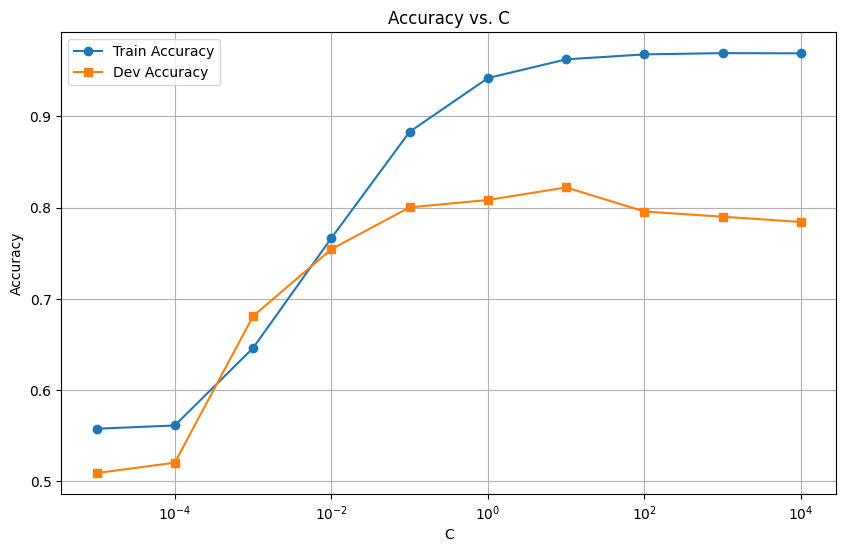

In [ ]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

C_values = [10 ** (-5 + i) for i in range(0,10)]

train_accuracies = []
dev_accuracies = []

for c in C_values:
  model = LogisticRegression(C=c, max_iter=1000)
  model.fit(X_train, y_train)

  y_train_pred = model.predict(X_train)
  train_acc = accuracy_score(y_train, y_train_pred)
  train_accuracies.append(train_acc)

  y_dev_pred = model.predict(X_dev)
  dev_acc = accuracy_score(y_dev, y_dev_pred)
  dev_accuracies.append(dev_acc)

  print(f"C = {c:<6} | 学習データ正解率: {train_acc:.4f} | 検証データ正解率: {dev_acc:.4f}")

plt.figure(figsize=(10, 6))
plt.plot(C_values, train_accuracies, label="Train Accuracy", marker='o')
plt.plot(C_values, dev_accuracies, label="Dev Accuracy", marker='s')
plt.xscale("log")
plt.xlabel("C")
plt.ylabel("Accuracy")
plt.title("Accuracy vs. C")
plt.legend()
plt.grid(True)
plt.show()


C = 7      | 学習データ正解率: 0.9608 | 検証データ正解率: 0.8119
C = 8      | 学習データ正解率: 0.9613 | 検証データ正解率: 0.8142
C = 9      | 学習データ正解率: 0.9623 | 検証データ正解率: 0.8211
C = 10     | 学習データ正解率: 0.9626 | 検証データ正解率: 0.8222
C = 11     | 学習データ正解率: 0.9633 | 検証データ正解率: 0.8188
C = 12     | 学習データ正解率: 0.9639 | 検証データ正解率: 0.8177
C = 13     | 学習データ正解率: 0.9640 | 検証データ正解率: 0.8154
C = 14     | 学習データ正解率: 0.9642 | 検証データ正解率: 0.8177


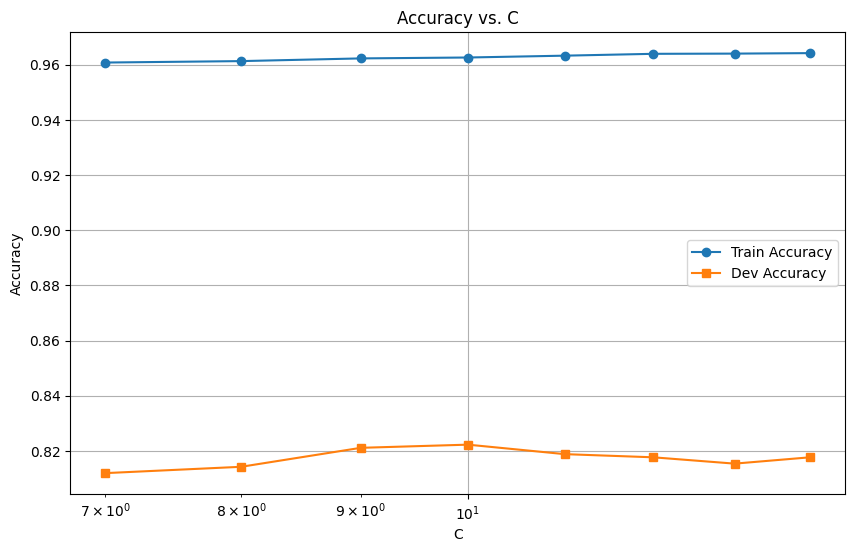

In [ ]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

C_values = [5 + 1 * i for i in range(2,10)]

train_accuracies = []
dev_accuracies = []

for c in C_values:
  model = LogisticRegression(C=c, max_iter=1000)
  model.fit(X_train, y_train)

  y_train_pred = model.predict(X_train)
  train_acc = accuracy_score(y_train, y_train_pred)
  train_accuracies.append(train_acc)

  y_dev_pred = model.predict(X_dev)
  dev_acc = accuracy_score(y_dev, y_dev_pred)
  dev_accuracies.append(dev_acc)

  print(f"C = {c:<6} | 学習データ正解率: {train_acc:.4f} | 検証データ正解率: {dev_acc:.4f}")

plt.figure(figsize=(10, 6))
plt.plot(C_values, train_accuracies, label="Train Accuracy", marker='o')
plt.plot(C_values, dev_accuracies, label="Dev Accuracy", marker='s')
plt.xscale("log")
plt.xlabel("C")
plt.ylabel("Accuracy")
plt.title("Accuracy vs. C")
plt.legend()
plt.grid(True)
plt.show()
